# 04 Restore: is a planted site diverging from a matched control?

This notebook walks through the `restore` app of `tessera_apps` on its two bundled demo sites:

- **Itapebi** (Bahia, Brazil, UTM 24S): a straight-edged block of about 62 ha, 3 km west of Itapebi, that was
  pasture through 2018 and became a plantation (most likely eucalyptus) from 2019.
- **Jaru** (Rondonia, Brazil, UTM 20S): a fenced paddock of about 32 ha, 5 km southeast of Jaru, cleared before 2000,
  where trees came back on their own from about 2019 (natural regrowth, no planting).

Each demo also carries a **negative site**, a pasture of the same size nearby that stayed pasture, which the app
should call quiet, and a **target**, a mature forest stand used as the "where a successful project is heading"
reference.

Everything runs on the TESSERA v1.1 annual embeddings: one 128-dimensional int8 vector per 10 m pixel per year,
2017 to 2025, read anonymously from the public Icechunk store. No GPU, no credentials, nothing trained. One run reads
about 1 GB of store chunks and takes 20 to 45 seconds from a container outside `us-west-2`.

## 1. What the app answers, and what it cannot

**Is a restoration or reforestation site following the trajectory a working project should, compared with a
matched control?**

The method, as the brief's section 4.4 was corrected by the pre-build survey (B5, S2, S16 to S19):

1. **Inputs.** The site polygon, the planting year, optionally a control polygon and a mature reference stand (the
   target). The trajectory runs from the baseline `year_a` (default `planted - 1`) to `year_b` (default 2025).
2. **The control.** Without `--control`, the app builds a ring 1 to 3 km from the site's edge and keeps only the ring
   pixels that looked like the site *before* the planting: their cosine similarity to the site's mean vector, in the
   match year (by default the year before the baseline), must be at least the 5th percentile of the site's own
   held-out similarities (site pixels split into 5 spatial folds of 200 m cells, each fold scored against the mean
   of the others).
3. **A fixed panel.** A pixel is used only if it has data in every trajectory year and the same radar pattern as the
   site's majority, so the yearly means never change composition and every comparison stays within one regime.
4. **Divergence.** Each year, `D(t) = 1 - cos(site mean, control mean)` and its change since the baseline,
   `dD(t) = D(t) - D(year_a)`.
5. **Placebos.** 200 site-sized pieces of the control (the kept control pixels within the site's equivalent radius of
   a random control pixel), each run exactly as the site is, against the rest of the control. Their 5th, 50th and
   95th percentiles per year form the band. A year is **significant** when the site's `dD` is above both the 95th
   percentile and zero.
6. **Verdict.** Over the years from `planted` to `year_b`: fewer than 3 of them is "insufficient years". Otherwise,
   if every year from some year Y to `year_b` is significant, and there are at least two such years, the verdict is
   "diverging from control since Y". Anything else is "no divergence detected".
7. **Target.** With a target: the site's similarity to the target mean, the control's (the 0 percent level) and the
   similarity of the target's two halves to each other (the 100 percent level), giving an unclipped progress.
8. **Per pixel.** The share of site pixels that sit below the control's own 5th percentile of similarity to the
   control mean (`departed_fraction`), and with a target, the share closer to the target than to the control.
9. **Validation** (`--validate`): the null test and a canopy height check against GLAD annual tree canopy height.

**The limitation, in plain words.** There is no global map of restoration outcomes to score the app against, the
way burn scars have fire perimeters or forest loss has Hansen. So this app has **no accuracy number**. What it has:

- a **null test**: the control split into two halves around the site and compared exactly as the site is. It should
  find nothing, and it does here, but finding nothing where nothing happened is a sanity check, not an accuracy;
- the **placebos**: site-sized pieces of the control, which set the band and give a false positive rate;
- a **canopy height check** against an independent model of tree height, which can only see trees of 5 m or more.

Divergence from the control says the site's embeddings moved away from comparable land that started like it. It
does not say the movement is the intended forest: that is for the target trajectory, the canopy check and, in the
end, a site visit.

In [1]:
from __future__ import annotations

import json
import logging
import subprocess
import sys
import time
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import shapely
from IPython.display import display
from matplotlib.colors import ListedColormap, PowerNorm
from matplotlib.patches import Patch
from pyproj import Transformer
from rasterio.features import rasterize

import tessera_apps
from tessera_apps import demo, io, validate
from tessera_apps.apps import restore as rs
from tessera_apps.apps import run_restore

# Show the app's own log lines (the run plan, "outputs are current", bytes read).
_handler = logging.StreamHandler()
_handler.setFormatter(logging.Formatter("%(levelname)s %(name)s: %(message)s"))
_log = logging.getLogger("tessera_apps")
_log.handlers[:] = [_handler]
_log.setLevel(logging.INFO)
_log.propagate = False

plt.rcParams.update({"figure.dpi": 72, "savefig.dpi": 72, "font.size": 10})
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)

# The four runs: (site argument, output directory). Each uses the demo's own target and --validate.
RUNS = {
    "itapebi": ("itapebi", Path("out/restore_itapebi")),
    "itapebi_negative": ("itapebi:negative", Path("out/restore_itapebi_negative")),
    "jaru": ("jaru", Path("out/restore_jaru")),
    "jaru_negative": ("jaru:negative", Path("out/restore_jaru_negative")),
}
EVIDENCE = Path("out/restore_evidence.json")

# Colours: three categorical hues (validated for colour-blind separation) plus neutral greys.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GREY, LIGHT, DARK = "#9a9993", "#dcdbd5", "#6f6e69"
ROLE_COLOURS = {1: ORANGE, 2: BLUE, 3: LIGHT, 4: GREY, 5: AQUA}
ROLE_LABELS = {
    1: "site (used)",
    2: "matched control",
    3: "ring rejected by the filter",
    4: "no match-year data, or dropped by the panel rule",
    5: "target",
}
print("tessera_apps", tessera_apps.__version__)


def report_of(key: str) -> dict:
    """The run's report JSON."""
    return json.loads((RUNS[key][1] / "restore_report.json").read_text(encoding="utf-8"))


def trajectory(rep: dict) -> pd.DataFrame:
    """The run's per-year table, indexed by year."""
    return pd.DataFrame(rep["summary"]["trajectory"]).set_index("year")


def placebo_changes(key: str) -> tuple[pd.DataFrame, pd.Series]:
    """Every placebo's divergence change per year (placebos x years) and whether the verdict rule calls it diverging."""
    p = pd.read_parquet(RUNS[key][1] / "restore_placebos.parquet")
    wide = p.pivot(index="placebo", columns="year", values="divergence_change")
    diverging = p.groupby("placebo")["verdict"].first().str.startswith("diverging")
    return wide, diverging


def load_cog(key: str) -> tuple[dict[str, np.ndarray], rasterio.Affine, rasterio.crs.CRS]:
    """Every band of the run's COG by name, with its transform and CRS."""
    tif = next(RUNS[key][1].glob("restore_*_*.tif"))
    with rasterio.open(tif) as src:
        bands = {name: src.read(i + 1) for i, name in enumerate(src.descriptions)}
        return bands, src.transform, src.crs


def km_frame(geom_lonlat: shapely.Geometry, crs: rasterio.crs.CRS, origin: tuple[float, float]) -> shapely.Geometry:
    """A lon/lat geometry in the COG's CRS, as km from ``origin`` (metres in that CRS)."""
    g = gpd.GeoSeries([geom_lonlat], crs=4326).to_crs(crs).iloc[0]
    ox, oy = origin
    return shapely.transform(g, lambda xy: (xy - np.array([ox, oy])) / 1000.0)


def draw_outline(ax: plt.Axes, geom: shapely.Geometry, **kw: object) -> None:
    """Plot every boundary line of a polygon or multipolygon."""
    for line in shapely.get_parts(geom.boundary):
        xy = np.asarray(line.coords)
        ax.plot(xy[:, 0], xy[:, 1], **kw)
        kw.pop("label", None)

tessera_apps 0.1.0


## 2. The demo sites, and why they are synthetic

The brief asks for a restoration site with a public boundary and a known planting year, from the Restor platform's
open projects or a US Forest Service reforestation polygon. **Neither could be reached from the build environment**
(USFS FACTS, Restor and the other candidate hosts are blocked), so both demo sites are **synthetic**: they are not
documented projects. They were located from independent public layers (GLAD annual tree canopy height 2015 to 2024,
Hansen Global Forest Change v1.13, ESA WorldCover and Sentinel-2 imagery) as places where land that was clearly
pasture became tree cover at a known time, next to land that did not.

That has three consequences you should keep in mind for everything below:

- **Itapebi is a plantation, not an ecological restoration.** Uniform heights and a block outline say eucalyptus. It
  stands in for "trees were planted here in 2019", which is the event the app must detect.
- **Jaru has no planting date.** Nobody planted it. `planted: 2019` in its file is the year the regrowth took hold,
  read from the canopy layer and imagery, and section 10 shows the embeddings disagree about that by a year.
- **The canopy check is not independent of the site choice.** The sites were picked with GLAD canopy height, so the
  canopy layer agrees with them by construction. The TESSERA embeddings are independent of it.

The properties each demo file carries:

In [2]:
rows = []
for name in demo.RESTORE_DEMOS:
    for role in ("aoi", "target", "negative"):
        p = demo.demo_feature_properties(name, role)
        rows.append(
            {
                "demo": name,
                "role": role,
                "name": p.get("name"),
                "planted": p.get("planted"),
                "area (ha)": p.get("area_ha"),
            }
        )
display(pd.DataFrame(rows).astype({"planted": "Int64"}).set_index(["demo", "role"]))
for name in demo.RESTORE_DEMOS:
    print(f"{name}: {demo.demo_feature_properties(name, 'aoi')['source']}\n")

name  planted  area (ha)
demo    role                                                                                                             
itapebi aoi              Itapebi, Bahia: eucalyptus planting on pasture (synthetic restore demo site)     2019       62.0
        target                                    Mature forest stand 4.4 km east of the Itapebi site     <NA>      154.1
        negative                      Pasture that stayed pasture, 1 km northwest of the Itapebi site     2019       62.7
jaru    aoi       Jaru, Rondonia: natural regrowth on abandoned pasture (synthetic restore demo site)     2019       32.1
        target                                  Mature forest stand 7.5 km southeast of the Jaru site     <NA>       24.8
        negative                            Pasture that stayed pasture, 3.5 km east of the Jaru site     2019       33.4

itapebi: Synthetic demo site, not a documented project: no planting record with a public polygon could be reached from the build environment (USFS FACTS, Restor and others are blocked), so this site was located from independent public layers (GLAD annual tree canopy height 2015 to 2024, Hansen GFC v1.13, ESA WorldCover, Sentinel-2 imagery). A straight-edged block about 62 ha, 3 km west of Itapebi in southern Bahia (UTM 24S): pasture through 2018, soil prepared in the July 2019 Sentinel-2 scene, young canopy by June 2020; GLAD canopy height is 0 on 99 percent of its pixels through 2020 and 5 m or more on 99 percent in 2021 (mean 6.3 m), 19 m by 2024. Uniform heights and the block outline say it is a plantation (likely eucalyptus), so it stands in for a tree planting, not an ecological restoration. No Hansen loss 2015 to 2025. The 1 to 3 km ring is 84 percent open pasture that stayed open.

jaru: Synthetic demo site, not a documented project: no planting record with a public polygon coul

### The evidence, recomputed

`scripts/check_restore_demos.py` recomputes the evidence behind every demo polygon from the public layers and the
store's cheap layers (scales and the two radar observation counts, no embeddings), for the site, the target, the
negative and the site's 1 to 3 km ring:

```
python scripts/check_restore_demos.py --out notebooks/out/restore_evidence.json
```

It read 48.6 MB of store chunks in 99.5 s (peak memory 0.37 GB). The cell below loads its JSON, or runs the script
when the file is missing.

In [3]:
if not EVIDENCE.is_file():
    subprocess.run([sys.executable, "../scripts/check_restore_demos.py", "--out", str(EVIDENCE)], check=True)
evidence = json.loads(EVIDENCE.read_text(encoding="utf-8"))
print(
    f"evidence: store snapshot {evidence['store_snapshot']}, {evidence['bytes_read'] / 1e6:.1f} MB of store chunks "
    f"in {evidence['wall_s']:.1f} s, written {evidence['created_utc']}"
)
POLY_ROLES = ("aoi", "target", "negative", "ring")


def top_classes(shares: dict, n: int = 2) -> str:
    """The n largest WorldCover classes, as 'class share' text."""
    best = sorted(shares.items(), key=lambda kv: -kv[1])[:n]
    return ", ".join(f"{k} {v:.0%}" for k, v in best if v >= 0.005)


overview, glad_rows, store_rows = [], {}, {}
for name, rec in evidence["demos"].items():
    for role in POLY_ROLES:
        ev = rec["polygons"][role]
        loss = ev["hansen"]["loss_pixels_by_year"]
        overview.append(
            {
                "demo": name,
                "polygon": role,
                "zone": ", ".join(ev["store"]["zones"]),
                "ha": round(ev["area_ha"], 1),
                "pixels": ev["pixels"],
                "Hansen treecover2000 (%)": round(ev["hansen"]["treecover2000_mean"], 1),
                "Hansen loss px 2001 to 2014": sum(v for y, v in loss.items() if int(y) < 2015),
                "Hansen loss px 2015 to 2025": sum(v for y, v in loss.items() if int(y) >= 2015),
                "WorldCover 2020": top_classes(ev["worldcover"]["2020"]),
                "WorldCover 2021": top_classes(ev["worldcover"]["2021"]),
            }
        )
        glad_rows[(name, role)] = {
            int(y): f"{v['mean_m']:.1f} m / {v['tall_share']:.0%}" for y, v in ev["glad_tch"].items()
        }
        store_rows[(name, role)] = {int(y): v["data_share"] for y, v in ev["store"]["per_year"].items()}
display(pd.DataFrame(overview).set_index(["demo", "polygon"]))
print("GLAD tree canopy height: mean height / share of pixels of 5 m or more")
display(pd.DataFrame(glad_rows).T)
print("TESSERA store: share of the polygon's pixels with data, per year")
display(pd.DataFrame(store_rows).T.apply(lambda col: col.map("{:.0%}".format)))

evidence: store snapshot RC6FS07ZB0T76EXT8XRG, 48.6 MB of store chunks in 99.5 s, written 2026-10-20T20:32:54+00:00


zone      ha  pixels  Hansen treecover2000 (%)  Hansen loss px 2001 to 2014  Hansen loss px 2015 to 2025                WorldCover 2020  \
demo    polygon                                                                                                                                            
itapebi aoi       24S    62.1    6200                       0.4                           84                            0  grassland 77%, tree cover 14%   
        target    24S   154.2   15435                      95.8                            0                            4                tree cover 100%   
        negative  24S    62.7    6267                       0.0                            0                            0                 grassland 100%   
        ring      24S  3174.2  317171                      17.0                        18039                         1985  grassland 83%, tree cover 11%   
jaru    aoi       20S    32.1    3185                       0.6                            0                            0  tree cover 78%, grassland 22%   
        target    20S    24.8    2483                      93.9                            0                            0                tree cover 100%   
        negative  20S    33.4    3364                       0.0                            0                            0                 grassland 100%   
        ring      20S  3003.0  300075                      14.3                        11756                        16741  grassland 77%, tree cover 20%   

                                WorldCover 2021  
demo    polygon                                  
itapebi aoi       tree cover 87%, grassland 13%  
        target                  tree cover 100%  
        negative                 grassland 100%  
        ring      grassland 84%, tree cover 13%  
jaru    aoi        tree cover 99%, grassland 1%  
        target                  tree cover 100%  
        negative                 grassland 100%  
        ring      grassland 71%, tree cover 27%

GLAD tree canopy height: mean height / share of pixels of 5 m or more


2015           2016           2017           2018           2019           2020           2021           2022           2023  \
itapebi aoi          0.0 m / 1%     0.0 m / 1%     0.0 m / 1%     0.0 m / 1%     0.0 m / 1%     0.1 m / 1%    6.4 m / 99%  11.3 m / 100%  16.3 m / 100%   
        target    22.6 m / 100%  22.6 m / 100%  22.6 m / 100%  22.6 m / 100%  22.6 m / 100%  22.6 m / 100%  22.6 m / 100%  22.6 m / 100%  22.6 m / 100%   
        negative     0.0 m / 0%     0.0 m / 0%     0.0 m / 0%     0.0 m / 0%     0.0 m / 0%     0.0 m / 0%     0.0 m / 0%     0.0 m / 0%     0.0 m / 0%   
        ring        1.8 m / 13%    1.8 m / 13%    1.7 m / 13%    1.8 m / 13%    1.7 m / 13%    1.8 m / 14%    1.9 m / 14%    1.9 m / 14%    2.0 m / 14%   
jaru    aoi          0.0 m / 0%     0.0 m / 0%     0.0 m / 0%     0.1 m / 1%     0.4 m / 7%    3.6 m / 63%    7.8 m / 91%   10.9 m / 94%   12.5 m / 96%   
        target    26.9 m / 100%  26.9 m / 100%  26.9 m / 100%  26.9 m / 100%  26.9 m / 100%  26.9 m / 100%  26.9 m / 100%  26.9 m / 100%  26.9 m / 100%   
        negative     0.0 m / 0%     0.0 m / 0%     0.0 m / 0%     0.0 m / 0%     0.0 m / 0%     0.0 m / 0%     0.0 m / 0%     0.0 m / 0%     0.0 m / 0%   
        ring        2.7 m / 20%    2.7 m / 19%    2.5 m / 19%    2.5 m / 18%    2.4 m / 18%    2.4 m / 18%    2.3 m / 18%    2.4 m / 18%    2.4 m / 18%   

                           2024  
itapebi aoi       19.3 m / 100%  
        target    22.6 m / 100%  
        negative     0.0 m / 0%  
        ring        2.0 m / 15%  
jaru    aoi        13.8 m / 97%  
        target    26.9 m / 100%  
        negative     0.0 m / 0%  
        ring        2.5 m / 18%

TESSERA store: share of the polygon's pixels with data, per year


2017  2018  2019  2020  2021  2022  2023  2024  2025
itapebi aoi        91%  100%  100%   98%  100%  100%  100%  100%  100%
        target     61%  100%  100%  100%  100%  100%  100%  100%  100%
        negative   14%  100%  100%  100%  100%  100%  100%  100%  100%
        ring       43%  100%  100%  100%  100%  100%  100%  100%  100%
jaru    aoi       100%  100%  100%  100%  100%  100%  100%  100%  100%
        target    100%  100%  100%  100%  100%  100%  100%  100%  100%
        negative  100%  100%  100%  100%  100%  100%  100%  100%  100%
        ring       91%  100%  100%  100%  100%  100%  100%  100%  100%

What the evidence says (10 m pixels; Hansen is 30 m resampled to them, nearest neighbour):

- **Itapebi site.** GLAD sees no tree of 5 m or more through 2020 (1% of pixels), then 99% in 2021 (mean 6.4 m),
  rising to 19.3 m by 2024. WorldCover calls it 77% grassland in 2020 and 87% tree cover in 2021. Hansen loss on it
  is old (84 pixels, 2001 to 2014) and there is none since 2015.
- **Itapebi target.** 22.6 m every year, Hansen tree cover 2000 of 96%, WorldCover tree cover. The check finds 4 pixels
  of Hansen loss in 2017 and 2018 where the demo file says none: less than half of one 30 m Hansen pixel, at the edge.
- **Itapebi negative.** 0 m in every year, 100% grassland. **Itapebi ring.** 83% grassland, 13 to 15% tall trees,
  steady.
- **Jaru site.** No tall trees through 2018 (1%), 7% in 2019, 63% in 2020, 91% in 2021, 13.8 m mean by 2024, with mixed
  heights (no planting rows). Never had Hansen loss. **Jaru ring.** Mostly pasture, with Hansen loss every year
  (an active clearing frontier). **Jaru negative.** 0 m every year, grassland.
- **The store.** Everything has data from 2018 on. **2017 is the gap**: the Itapebi ring has data on 43% of its
  pixels, the Itapebi negative on 14%, the Itapebi target on 61%. That matters, because 2017 is the year the control
  is matched on (section 4).

One property of the canopy layer to know before section 8: **a stable mature stand has exactly the same height every
year** (the Jaru target is 26.93 m in all ten years). GLAD's annual heights come from a model that tracks change
(loss and regrowth) against a fixed baseline, so they are not ten independent measurements of a stable stand.

## 3. Run it

From a shell, each run is one command. These are the commands that produced the outputs used below, from a container
outside `us-west-2` with every `AWS_*` variable unset (the store is anonymous):

```
tessera-apps restore --aoi itapebi --target demo --validate --out notebooks/out/restore_itapebi
tessera-apps restore --aoi itapebi:negative --target demo --validate --out notebooks/out/restore_itapebi_negative
tessera-apps restore --aoi jaru --target demo --validate --out notebooks/out/restore_jaru
tessera-apps restore --aoi jaru:negative --target demo --validate --out notebooks/out/restore_jaru_negative
```

`--aoi itapebi` loads the demo's site with its properties, so `planted` (2019) comes from the file: the run uses
`year_a` 2018 (the baseline), `year_b` 2025 and match year 2017. `--aoi itapebi:negative` loads the demo's negative
feature as the site, with its own properties. `--target demo` resolves against the same demo file.

In Python it is one call per run. The runs are idempotent: when the output directory already holds outputs that the
report says were written with the same arguments, site, code and store snapshot, the call reads only the store's
metadata and returns at once with `skipped` set. Delete the directory or pass `force=True` to recompute (about 2
minutes and 3.7 GB of reads for all four).

In [4]:
results = {}
for key, (site, out) in RUNS.items():
    t0 = time.perf_counter()
    results[key] = run_restore(site, out, target="demo", validate=True)
    print(f"{key:17s} skipped (outputs current): {results[key].skipped}, in {time.perf_counter() - t0:.1f} s")
res = results["itapebi"]
for path in [
    res.paths.tif,
    res.paths.summary_parquet,
    res.paths.summary_csv,
    *res.extra_paths.values(),
    res.paths.preview,
    res.paths.validation,
    res.paths.report,
]:
    print(f"  {path.name:28s} {path.stat().st_size / 1e6:8.2f} MB")

INFO tessera_apps.apps._common: restore: AOI demo:itapebi, 3,240 ha in 1 zone(s) (24S 709 x 718), 323,981 pixels; years 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025; at most 0.98 GB of chunks to read.


INFO tessera_apps.apps._common: restore: peak memory about 2.6 GB (15.8 GB available).


INFO tessera_apps.apps.restore: restore: site 6200 pixels, ring 317171 pixels, target 15435 pixels; planted 2019, years 2018 to 2025, control matched on 2017.


INFO tessera_apps.apps._common: restore: removed the previous run's restore_report.json, restore_validation.json.


WARNING tessera_apps.apps._common: restore: The control is matched on 2017, the store's first year (the year before the baseline 2018): it has few Sentinel-2 observations and sparse valid pixels in places (survey S16), so the control match rests on a weak year.


...

WARNING tessera_apps.apps._common: restore: The control is matched on 2017, the store's first year (the year before the baseline 2018): it has few Sentinel-2 observations and sparse valid pixels in places (survey S16), so the control match rests on a weak year.


INFO tessera_apps.apps.restore: restore: 2017 data in 3360 of 3364 site, 291382 of 297130 ring and 2483 of 2483 target pixels.


WARNING tessera_apps.apps._common: restore: 1 of 228,442 control pixels were dropped: 1 lack data in some year from 2018 to 2025 (the panel rule) and 0 have another radar pattern than the site's majority (survey B5).


INFO tessera_apps.apps._common: restore: read 1.04 GB in 24.0 s (43 MB/s).


jaru_negative     skipped (outputs current): False, in 24.0 s
  restore_2018_2025.tif            2.19 MB
  restore_summary.parquet          0.02 MB
  restore_summary.csv              0.00 MB
  restore_placebos.parquet         0.04 MB
  restore_preview.png              0.26 MB
  restore_validation.json          0.01 MB
  restore_report.json              0.04 MB


In [5]:
reports = {key: report_of(key) for key in RUNS}
head = {}
for key, rep in reports.items():
    s = rep["summary"]
    null, canopy, ctrl = s["null_test"], s["canopy"] or {}, s["control"]
    head[key] = {
        "verdict": s["verdict"],
        "significant years": ", ".join(str(y) for y in s["significant_years"]) or "none",
        "max dD after planting": f"{max(r['divergence_change'] for r in s['trajectory'] if r['post_planting']):+.4f}",
        "placebo false positive rate": f"{s['placebo_false_positive_rate']:.1%}",
        "null test": f"{null['null_verdict']}, max |dD| {null['null_max_abs_change']:.5f}, "
        f"ratio to site {null['null_to_site_ratio']:.3f}",
        "canopy onset year": canopy.get("canopy_onset_year"),
        "dD vs canopy gap (Pearson / Spearman)": f"{canopy.get('pearson_divergence_vs_mean_gap_change'):+.2f} / "
        f"{canopy.get('spearman_divergence_vs_mean_gap_change'):+.2f}",
        "site / control pixels used": f"{s['site']['pixels_used']:,} / {s['regime']['dropped']['control']['used']:,}",
        "warnings": len(rep["warnings"]),
        "bytes read": f"{rep['bytes_read'] / 1e9:.2f} GB",
        "wall": f"{rep['timings']['wall_s']:.0f} s",
    }
display(pd.DataFrame(head))

,itapebi,itapebi_negative,jaru,jaru_negative
verdict,diverging from control since 2019,no divergence detected,diverging from control since 2020,no divergence detected
significant years,"2019, 2020, 2021, 2022, 2023, 2024, 2025",none,"2020, 2021, 2022, 2023, 2024, 2025",2021
max dD after planting,+0.4707,+0.0119,+0.0644,+0.0107
placebo false positive rate,2.5%,5.0%,1.0%,2.0%
null test,"no divergence detected, max |dD| 0.01039, ratio to site 0.022","no divergence detected, max |dD| 0.00587, ratio to site 0.343","no divergence detected, max |dD| 0.00017, ratio to site 0.003","no divergence detected, max |dD| 0.00033, ratio to site 0.031"
canopy onset year,2021,None,2020,None
dD vs canopy gap (Pearson / Spearman),+0.70 / +0.75,-0.10 / +0.04,+0.97 / +0.96,-0.49 / -0.39
site / control pixels used,"6,095 / 9,299","6,267 / 93,966","3,185 / 163,863","3,364 / 228,441"
warnings,5,4,2,2
bytes read,0.77 GB,0.89 GB,1.03 GB,1.04 GB


The planted site (Itapebi) and the regrowth site (Jaru) are both called diverging; both negative sites are called
quiet; every null test finds nothing. The rest of the notebook asks whether those calls are earned, starting with
the control they are measured against. Sections 4 to 8 follow the Itapebi site; section 9 the two negatives;
section 10 Jaru.

## 4. The control: a ring, filtered on the year before the baseline

The control candidates are every pixel 1 to 3 km from the site's edge (less the target). The filter keeps the ones
that looked like the site **before** anything happened:

- The **match year** is 2017, the year before the 2018 baseline. Matching on the baseline itself would select ring
  pixels that pass by the luck of that year's noise; they drift back the next year (regression to the mean), and
  that drift would read as divergence of a site that did nothing. Matching one year earlier puts that drift between
  2017 and 2018, outside `dD`, and the report measures it (`selection_drift`).
- The **site mean** is the mean of the site's 2017 vectors (the 5,616 of its 6,200 pixels with 2017 data).
- The **threshold** is the 5th percentile of the site pixels' *held-out* similarities: the site's pixels are blocked
  into 200 m cells (28 cells here), the cells into 5 folds, and each fold is scored against the mean of the other
  four. An in-sample percentile would be too tight, since every pixel helped make the mean it is scored against.
- A ring pixel without 2017 data cannot be filtered, so it is left out.

The map shows the result (km from the site's centroid). The histogram is the COG's `baseline_similarity` band, which
holds each pixel's 2017 similarity to the site's 2017 mean.

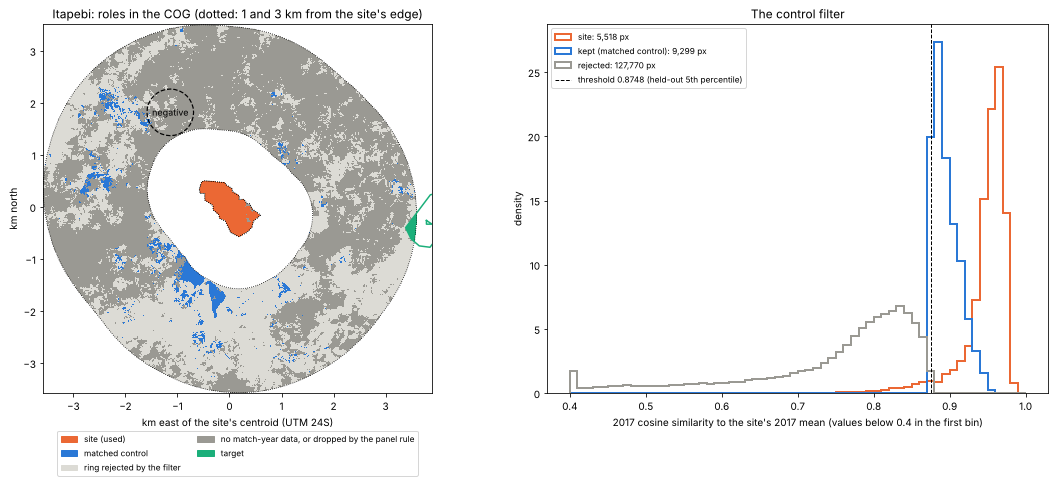

In [6]:
bands, T, CRS = load_cog("itapebi")
role = bands["role"]
H, W = role.shape
site_geom = demo.demo_feature("itapebi", "aoi")
centre = gpd.GeoSeries([site_geom], crs=4326).to_crs(CRS).iloc[0].centroid
ORIGIN = (centre.x, centre.y)
EXT = [
    (T.c - ORIGIN[0]) / 1e3,
    (T.c + W * T.a - ORIGIN[0]) / 1e3,
    (T.f + H * T.e - ORIGIN[1]) / 1e3,
    (T.f - ORIGIN[1]) / 1e3,
]
zone = rs.main_zone(site_geom)
outlines = {
    "site": km_frame(site_geom, CRS, ORIGIN),
    "ring 1 km": km_frame(rs.ring_geometry(site_geom, 0.0, 1.0, zone=zone), CRS, ORIGIN),
    "ring 3 km": km_frame(rs.ring_geometry(site_geom, 0.0, 3.0, zone=zone), CRS, ORIGIN),
    "target": km_frame(demo.demo_feature("itapebi", "target"), CRS, ORIGIN),
    "negative": km_frame(demo.demo_feature("itapebi", "negative"), CRS, ORIGIN),
}

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(15, 6.6), gridspec_kw={"width_ratios": [1.05, 1]}, layout="constrained")
cmap = ListedColormap([ROLE_COLOURS[k] for k in range(1, 6)]).with_extremes(bad="white")
ax0.imshow(np.ma.masked_invalid(role), cmap=cmap, vmin=0.5, vmax=5.5, extent=EXT, interpolation="nearest")
draw_outline(ax0, outlines["ring 1 km"], color="black", linewidth=0.8, linestyle=":")
draw_outline(ax0, outlines["ring 3 km"], color="black", linewidth=0.8, linestyle=":")
draw_outline(ax0, outlines["target"], color=AQUA, linewidth=1.5)
draw_outline(ax0, outlines["negative"], color="black", linewidth=1.2, linestyle="--")
ax0.text(*outlines["negative"].centroid.coords[0], "negative", ha="center", va="center", fontsize=9)
ax0.set_xlim(EXT[0], EXT[1] + 0.3)
ax0.set_xlabel("km east of the site's centroid (UTM 24S)")
ax0.set_ylabel("km north")
ax0.legend(
    handles=[Patch(color=ROLE_COLOURS[k], label=ROLE_LABELS[k]) for k in ROLE_LABELS],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.09),
    ncol=2,
    fontsize="small",
)
ax0.set_title("Itapebi: roles in the COG (dotted: 1 and 3 km from the site's edge)")

sim = bands["baseline_similarity"]
thr = reports["itapebi"]["summary"]["control"]["threshold_similarity"]
bins = np.linspace(0.4, 1.0, 61)
for code_, colour, label in ((1, ORANGE, "site"), (2, BLUE, "kept (matched control)"), (3, GREY, "rejected")):
    v = sim[(role == code_) & np.isfinite(sim)]
    ax1.hist(
        np.clip(v, 0.4, 1.0),
        bins=bins,
        density=True,
        histtype="step",
        linewidth=2,
        color=colour,
        label=f"{label}: {v.size:,} px",
    )
ax1.axvline(thr, color="black", linewidth=1, linestyle="--", label=f"threshold {thr:.4f} (held-out 5th percentile)")
ax1.set_xlabel("2017 cosine similarity to the site's 2017 mean (values below 0.4 in the first bin)")
ax1.set_ylabel("density")
ax1.legend(loc="upper left", fontsize="small")
ax1.set_title("The control filter")
plt.show()

In [7]:
c = reports["itapebi"]["summary"]["control"]
bal = c["balance"]
cover = reports["itapebi"]["summary"]["match_year_data"]
with_data = c["candidate_pixels_valid_match_year"]
site_cover = cover["site"]
pd.Series(
    {
        "ring candidate pixels": f"{c['candidate_pixels']:,}",
        "with 2017 data": f"{with_data:,} ({cover['ring']['share_with_data']:.0%})",
        "kept (matched control)": f"{c['kept_pixels']:,} ({c['kept_pixels'] / with_data:.1%} of those with data)",
        "rejected by the filter": f"{c['rejected_pixels']:,}",
        "threshold (2017 similarity)": f"{c['threshold_similarity']:.4f}, {c['threshold_source']}, "
        f"{c['folds']} folds of {c['site_cells']} cells",
        "site pixels with 2017 data": f"{site_cover['with_data']:,} of {site_cover['pixels']:,} "
        f"({site_cover['share_with_data']:.0%})",
        "D in 2017 (match year)": f"{c['match_year_divergence']:.5f}",
        "D in 2018 (baseline), same pixels": f"{c['baseline_divergence_match_pixels']:.5f}",
        "selection drift (2017 to 2018)": f"{c['selection_drift']:+.5f}",
        "baseline D, rank among the placebos'": f"{bal['baseline_divergence']:.5f}, above "
        f"{bal['baseline_divergence_rank']:.0%} of them (median {bal['placebo_baseline_divergence_p50']:.5f})",
    },
    name="Itapebi control",
).to_frame()

,Itapebi control
ring candidate pixels,"317,171"
with 2017 data,"137,101 (43%)"
kept (matched control),"9,331 (6.8% of those with data)"
rejected by the filter,"127,770"
threshold (2017 similarity),"0.8748, heldout, 5 folds of 28 cells"
site pixels with 2017 data,"5,616 of 6,200 (91%)"
D in 2017 (match year),0.05024
"D in 2018 (baseline), same pixels",0.04885
selection drift (2017 to 2018),-0.00139
"baseline D, rank among the placebos'","0.04916, above 76% of them (median 0.02826)"


Three things to read from this:

- **The control is a narrow, well matched slice of the ring.** The site's own 2017 pixels sit near 0.96 to their
  mean, while most of the ring's pasture sits near 0.8: only 9,331 of the 137,101 ring pixels with 2017 data (6.8%)
  are as close to the site as the site's own 5th percentile. The site's pasture was not a typical pasture of the
  ring. The 9,299 that survive the panel rule are still 1.5 times the site's pixel count.
- **2017 decides where the control can come from.** Only 43% of the ring has 2017 data (the grey area to the north
  and east), so every control pixel lies where 2017 had clear views, mostly south and west of the site. The run warns
  about this. `--match-year 2018` would cover the whole ring but match on the baseline itself (and warn about
  regression to the mean); with a 2018 baseline there is no better year.
- **The selection drift is small** (-0.0014), so the control did not drift back toward the ring's typical pasture
  between 2017 and 2018. At the baseline the site is a little less like its control (D 0.049) than the median placebo
  piece of the control is (0.028), above 76% of them.

## 5. The divergence trajectory

The plot shows the site's `dD` (the change of `1 - cos(site mean, control mean)` since 2018), the 200 placebos in
light grey (the ones the verdict rule would call diverging are darker), their 5 to 95 percentile band, and the null
pair: the control split into two halves by 8 alternating angular sectors around the site, compared exactly as the
site is. The right panel is the same with the vertical axis cut to the band, to show the first years.

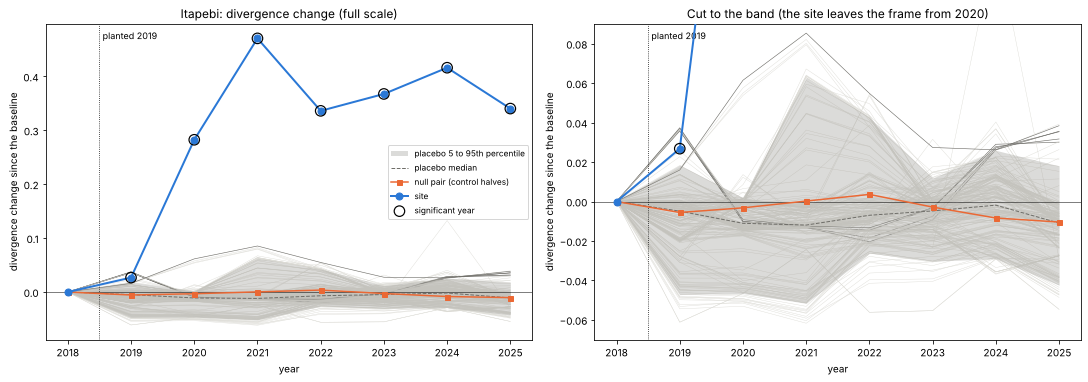

,post_planting,divergence,divergence_change,placebo_p05,placebo_p50,placebo_p95,significant,null_divergence_change
year,,,,,,,,
2018,False,0.0492,0.0000,0.0000,0.0000,0.0000,False,0.0000
2019,True,0.0760,0.0268,-0.0471,-0.0049,0.0185,True,-0.0055
2020,True,0.3317,0.2825,-0.0466,-0.0110,0.0020,True,-0.0032
2021,True,0.5199,0.4707,-0.0516,-0.0119,0.0629,True,0.0002
2022,True,0.3854,0.3362,-0.0261,-0.0070,0.0427,True,0.0036
2023,True,0.4167,0.3676,-0.0302,-0.0048,0.0119,True,-0.0028
2024,True,0.4654,0.4162,-0.0290,-0.0018,0.0260,True,-0.0084
2025,True,0.3896,0.3404,-0.0424,-0.0109,0.0181,True,-0.0104


verdict: diverging from control since 2019 | The divergence change exceeds the placebo band's 95th percentile in every year from 2019 to 2025 (7 years).
placebo false positive rate: 2.5% (5 of 200)
null test: no divergence detected; max |dD| 0.01039 against the site's 0.47071 (ratio 0.022); halves of 2,474 and 6,825 pixels, the smaller 0.41 times the site's
trend after planting: Theil-Sen 0.0314 per year (95% interval -0.0326 to 0.1031), Spearman rho 0.54 (p 0.22)


In [8]:
def trajectory_panel(
    ax: plt.Axes,
    key: str,
    *,
    ylim: tuple[float, float] | None = None,
    title: str = "",
    show_placebos: bool = True,
) -> None:
    """The site's divergence change, the placebos, their band and the null pair, for one run."""
    tr = trajectory(reports[key])
    years = tr.index.to_numpy()
    if show_placebos:
        wide, diverging = placebo_changes(key)
        for k, row in wide.iterrows():
            ax.plot(
                years,
                row.to_numpy(),
                color=DARK if diverging[k] else LIGHT,
                linewidth=0.6 if diverging[k] else 0.4,
                zorder=1,
            )
    ax.fill_between(
        years,
        tr["placebo_p05"],
        tr["placebo_p95"],
        color=GREY,
        alpha=0.35,
        linewidth=0,
        label="placebo 5 to 95th percentile",
        zorder=2,
    )
    ax.plot(years, tr["placebo_p50"], color=DARK, linestyle="--", linewidth=1, label="placebo median", zorder=3)
    ax.plot(
        years,
        tr["null_divergence_change"],
        color=ORANGE,
        marker="s",
        markersize=5,
        linewidth=1.5,
        label="null pair (control halves)",
        zorder=4,
    )
    ax.plot(years, tr["divergence_change"], color=BLUE, marker="o", markersize=7, linewidth=2, label="site", zorder=5)
    sig = tr["significant"].to_numpy()
    ax.scatter(
        years[sig],
        tr["divergence_change"].to_numpy()[sig],
        s=110,
        facecolors="none",
        edgecolors="black",
        linewidths=1.2,
        label="significant year",
        zorder=6,
    )
    planted = reports[key]["summary"]["planted"]
    ax.axvline(planted - 0.5, color="black", linewidth=0.8, linestyle=":")
    ax.text(planted - 0.45, 0.98, f"planted {planted}", transform=ax.get_xaxis_transform(), va="top", fontsize=9)
    ax.axhline(0, color="black", linewidth=0.5)
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.set_xlabel("year")
    ax.set_ylabel("divergence change since the baseline")
    ax.set_title(title)


fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), layout="constrained")
trajectory_panel(axes[0], "itapebi", title="Itapebi: divergence change (full scale)")
trajectory_panel(axes[1], "itapebi", ylim=(-0.07, 0.09), title="Cut to the band (the site leaves the frame from 2020)")
axes[0].legend(loc="center right", fontsize="small")
plt.show()
cols = [
    "post_planting",
    "divergence",
    "divergence_change",
    "placebo_p05",
    "placebo_p50",
    "placebo_p95",
    "significant",
    "null_divergence_change",
]
display(trajectory(reports["itapebi"])[cols])
s = reports["itapebi"]["summary"]
print("verdict:", s["verdict"], "|", s["verdict_detail"])
pl = s["placebos"]
print(
    f"placebo false positive rate: {s['placebo_false_positive_rate']:.1%} ({pl['diverging_placebos']} of {pl['count']})"
)
n = s["null_test"]
print(
    f"null test: {n['null_verdict']}; max |dD| {n['null_max_abs_change']:.5f} against the site's "
    f"{n['site_max_abs_change']:.5f} (ratio {n['null_to_site_ratio']:.3f}); "
    f"halves of {n['half_pixels'][0]:,} and {n['half_pixels'][1]:,} pixels, "
    f"the smaller {n['half_to_site_pixels']:.2f} times the site's"
)
t = s["trend"]
print(
    f"trend after planting: Theil-Sen {t['theil_sen_slope']:.4f} per year (95% interval {t['theil_sen_low']:.4f} to "
    f"{t['theil_sen_high']:.4f}), Spearman rho {t['spearman_rho']:.2f} (p {t['spearman_p']:.2f})"
)

**The planted site diverges, and from the planting year.** `dD` is 0.027 in 2019, just above the band's 95th
percentile (0.018); the demo's notes put soil preparation in the July 2019 Sentinel-2 scene, so the 2019 annual
embedding already sees bare, worked ground for part of the year. In 2020, a year before any tree reaches 5 m, `dD` is
0.28, and it peaks at 0.47 in 2021. Every year from 2019 to 2025 is significant: "diverging from control since 2019".

What else the numbers say:

- **The band is honest about its own noise.** 5 of the 200 placebos (2.5%) pass the same verdict rule. That rate is
  capped near 5% by construction (the placebos make the band they are judged against), so it shows that the run
  requirement works, not that the band is calibrated for this site.
- **The null pair is flat** (largest change 0.010, 2% of the site's). Its halves hold 2,474 and 6,825 pixels, because
  the kept control clusters where 2017 had data; the smaller half is 0.41 times the site, so here the halves are
  not far larger than the site (the report's caveat and the CLI line say so when a half is under twice the site's
  pixels). This null is a little harder than usual, and it still passes.
- **The trajectory is a step, not a trend.** After 2021 `dD` falls back to 0.34 and wobbles between 0.34 and 0.42
  while the trees keep growing (section 8). The Theil-Sen slope (0.031 per year, interval -0.033 to 0.103) and
  Spearman rho (0.54, p 0.22) are weak because a jump in 2020 and 2021 followed by a plateau is not a monotone
  trend. For a planting that changes land cover at once, read the verdict and the band, not the slope.
- The placebos are smaller than the site (a median of 924 pixels against 6,095, because the kept control is sparse
  within the site's 444 m radius). Smaller placebos have noisier means, so the band is wider than a site-sized one
  would be; a change in per-pixel spread between years can also shift it, which is why a year counts only when `dD`
  is above both the band and zero.

## 6. The target trajectory: how far toward a mature stand?

The target is a 154 ha stand of mature Atlantic forest 4.4 km east of the site (GLAD 22.6 m on every pixel in every
year). Per year:

- `s_T`: cosine similarity of the site mean to the target mean;
- `c_T`: the same for the control mean, the 0 percent level;
- `tau`: the similarity of the target's two halves (split by a line through its centroid across its long axis) to
  each other, the 100 percent level: as close as one end of the stand is to the other.

`progress = (s_T - c_T) / (tau - c_T)`, reported unclipped.

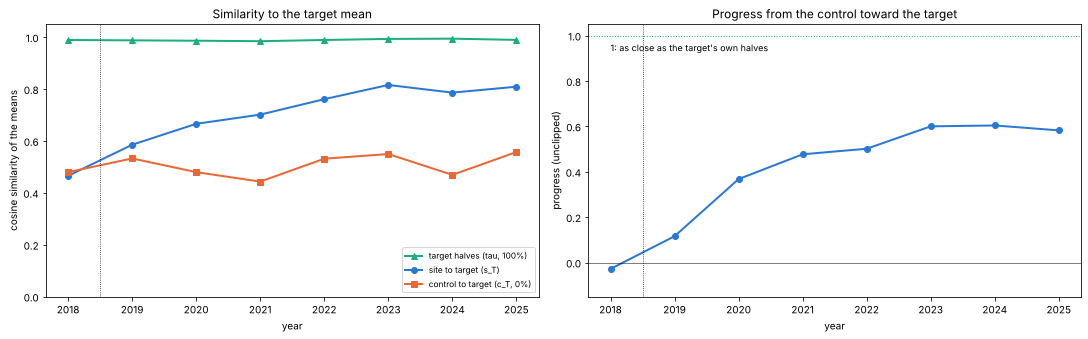

,target_similarity,control_target_similarity,target_halves_similarity,target_progress
year,,,,
2018,0.4656,0.4799,0.9893,-0.0281
2019,0.5854,0.5326,0.9878,0.1160
2020,0.6661,0.4798,0.9865,0.3677
2021,0.7015,0.4433,0.9846,0.4770
2022,0.7611,0.5316,0.9892,0.5014
2023,0.8158,0.5495,0.9933,0.6001
2024,0.7864,0.4693,0.9943,0.6040
2025,0.8091,0.5572,0.9896,0.5824


In [9]:
tr = trajectory(reports["itapebi"])
years = tr.index.to_numpy()
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained")
ax0.plot(years, tr["target_halves_similarity"], color=AQUA, marker="^", linewidth=2, label="target halves (tau, 100%)")
ax0.plot(years, tr["target_similarity"], color=BLUE, marker="o", linewidth=2, label="site to target (s_T)")
ax0.plot(
    years, tr["control_target_similarity"], color=ORANGE, marker="s", linewidth=2, label="control to target (c_T, 0%)"
)
ax0.axvline(2018.5, color="black", linewidth=0.8, linestyle=":")
ax0.set_ylim(0, 1.05)
ax0.set_xlabel("year")
ax0.set_ylabel("cosine similarity of the means")
ax0.legend(loc="lower right", fontsize="small")
ax0.set_title("Similarity to the target mean")
ax1.plot(years, tr["target_progress"], color=BLUE, marker="o", linewidth=2, label="Itapebi site")
ax1.axhline(0, color="black", linewidth=0.5)
ax1.axhline(1, color=AQUA, linewidth=1, linestyle=":")
ax1.text(years[0], 0.97, "1: as close as the target's own halves", va="top", fontsize=9)
ax1.axvline(2018.5, color="black", linewidth=0.8, linestyle=":")
ax1.set_ylim(-0.15, 1.05)
ax1.set_xlabel("year")
ax1.set_ylabel("progress (unclipped)")
ax1.set_title("Progress from the control toward the target")
plt.show()
display(tr[["target_similarity", "control_target_similarity", "target_halves_similarity", "target_progress"]])

Progress is -0.03 at the 2018 baseline (the site starts as far from the forest as its control), 0.12 in 2019, 0.37
in 2020, 0.48 in 2021 and about 0.6 from 2023 to 2025. The control stays put (`c_T` between 0.44 and 0.56, moving
with the year), and the target's halves stay at 0.98 to 0.99 of each other.

Read the plateau at 0.6 with care. The target is native forest and the site is a six-year-old monoculture: the
progress says the plantation's embeddings are 60% of the way from pasture to that forest, not that it is 60% of a
forest. A plantation target (a mature eucalyptus stand) would be the right reference for "is this planting on
track"; a native stand is the right one for "is this becoming forest". The app takes whichever you pass.

## 7. The per-pixel fractions over time

The trajectories above compare means. The brief's step 5 asks for the number a buyer wants, per pixel:

- **`closer_to_target_fraction`**: the share of site pixels whose cosine to the target mean exceeds their cosine to
  the control mean, with the same share for control pixels as its null;
- **`departed_fraction`**: the share of site pixels whose cosine to the control mean is below the 5th percentile of
  the control pixels' own cosines to it. A site that did nothing sits near 0.05 (not exactly: the control filter
  trims the control's low tail in 2017, and part of that trim persists), so read its change since the baseline.

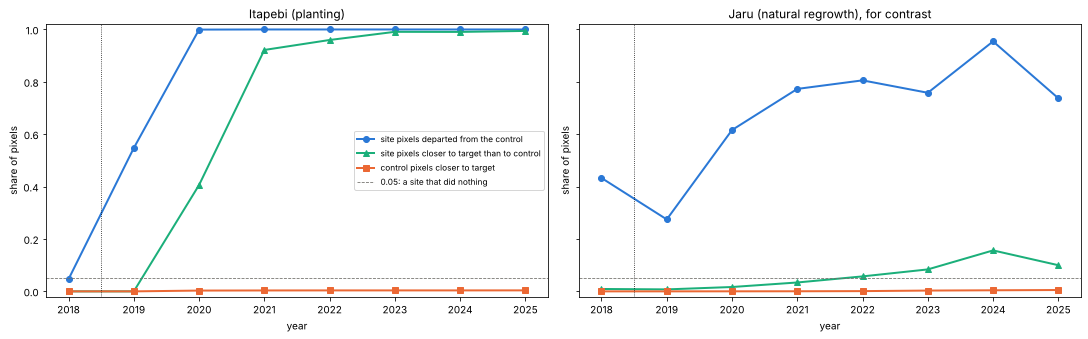

itapebi                                                                                                   jaru                           \
     departed_fraction departed_fraction_change closer_to_target_fraction control_closer_to_target_fraction departed_fraction departed_fraction_change   
year                                                                                                                                                     
2018            0.0466                   0.0000                    0.0000                            0.0000            0.4330                   0.0000   
2019            0.5473                   0.5007                    0.0000                            0.0000            0.2747                  -0.1582   
2020            0.9995                   0.9529                    0.4061                            0.0030            0.6160                   0.1830   
2021            1.0000                   0.9534                    0.9217                            0.0034            0.7730                   0.3400   
2022            1.0000                   0.9534                    0.9598                            0.0037            0.8057                   0.3727   
2023            1.0000                   0.9534                    0.9910                            0.0037            0.7582                   0.3253   
2024            1.0000                   0.9534                    0.9906                            0.0037            0.9545                   0.5215   
2025            1.0000                   0.9534                    0.9944                            0.0038            0.7372                   0.3042   

                                                                  
     closer_to_target_fraction control_closer_to_target_fraction  
year                                                              
2018                    0.0091                        6.1027e-06  
2019                    0.0075                        4.2719e-05  
2020                    0.0166                        1.6477e-04  
2021                    0.0339                        3.7226e-04  
2022                    0.0571                        9.4591e-04  
2023                    0.0838                        3.0330e-03  
2024                    0.1564                        4.1132e-03  
2025                    0.0998                        5.1323e-03

In [10]:
def fractions_panel(ax: plt.Axes, key: str, title: str) -> None:
    """Departed and closer-to-target fractions per year, for one run."""
    tr = trajectory(reports[key])
    years = tr.index.to_numpy()
    ax.plot(
        years,
        tr["departed_fraction"],
        color=BLUE,
        marker="o",
        linewidth=2,
        label="site pixels departed from the control",
    )
    ax.plot(
        years,
        tr["closer_to_target_fraction"],
        color=AQUA,
        marker="^",
        linewidth=2,
        label="site pixels closer to target than to control",
    )
    ax.plot(
        years,
        tr["control_closer_to_target_fraction"],
        color=ORANGE,
        marker="s",
        linewidth=2,
        label="control pixels closer to target",
    )
    ax.axhline(0.05, color=DARK, linewidth=0.8, linestyle="--", label="0.05: a site that did nothing")
    ax.axvline(reports[key]["summary"]["planted"] - 0.5, color="black", linewidth=0.8, linestyle=":")
    ax.set_ylim(-0.02, 1.02)
    ax.set_xlabel("year")
    ax.set_ylabel("share of pixels")
    ax.set_title(title)


fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained", sharey=True)
fractions_panel(axes[0], "itapebi", "Itapebi (planting)")
fractions_panel(axes[1], "jaru", "Jaru (natural regrowth), for contrast")
axes[0].legend(loc="center right", fontsize="small")
plt.show()
display(
    pd.concat(
        {
            key: trajectory(reports[key])[
                [
                    "departed_fraction",
                    "departed_fraction_change",
                    "closer_to_target_fraction",
                    "control_closer_to_target_fraction",
                ]
            ]
            for key in ("itapebi", "jaru")
        },
        axis=1,
    )
)

The same, as maps: each site pixel's distance from the control mean (`1 - similarity_to_control_<year>`, from the
COG) for five years, with a square-root colour scale so the small Jaru changes stay visible next to the large
Itapebi ones. The last column is the COG's `closer_to_target_2025` band. The white holes at the east edge of the
Itapebi block are the 105 pixels the panel rule dropped (no data in 2020).

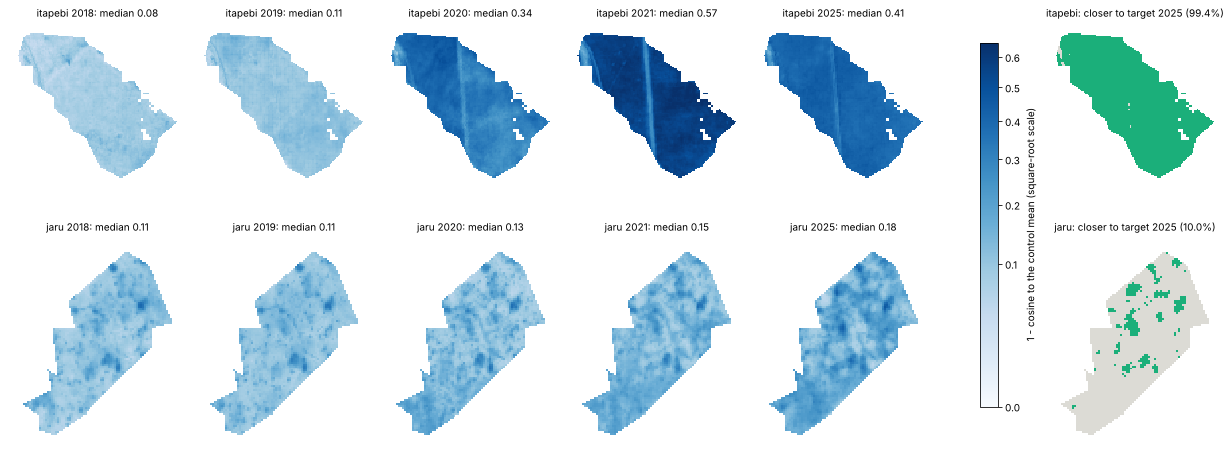

In [11]:
def site_window(key: str, pad: int = 8) -> tuple[dict[str, np.ndarray], tuple[slice, slice]]:
    """The run's COG bands and a window around its site pixels."""
    b, _, _ = load_cog(key)
    rr, cc = np.nonzero(b["role"] == 1)
    win = (slice(max(rr.min() - pad, 0), rr.max() + pad + 1), slice(max(cc.min() - pad, 0), cc.max() + pad + 1))
    return b, win


SHOW_YEARS = (2018, 2019, 2020, 2021, 2025)
norm = PowerNorm(gamma=0.5, vmin=0.0, vmax=0.65)
fig, axes = plt.subplots(2, len(SHOW_YEARS) + 1, figsize=(17, 6.4), layout="constrained")
for row, key in enumerate(("itapebi", "jaru")):
    b, win = site_window(key)
    site_px = b["role"][win] == 1
    for k, year in enumerate(SHOW_YEARS):
        ax = axes[row, k]
        dist = np.where(site_px, 1.0 - b[f"similarity_to_control_{year}"][win], np.nan)
        im = ax.imshow(dist, cmap="Blues", norm=norm, interpolation="nearest")
        ax.set_title(f"{key} {year}: median {np.nanmedian(dist):.2f}", fontsize=10)
        ax.set_axis_off()
    ax = axes[row, -1]
    ax.set_axis_off()
    closer = np.where(site_px, b["closer_to_target_2025"][win], np.nan)
    ax.imshow(closer, cmap=ListedColormap([LIGHT, AQUA]), vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(f"{key}: closer to target 2025 ({np.nanmean(closer):.1%})", fontsize=10)
fig.colorbar(im, ax=axes[:, : len(SHOW_YEARS)], shrink=0.8, label="1 - cosine to the control mean (square-root scale)")
plt.show()

At Itapebi the whole block moves at once (a straight line one or two pixels wide crosses it in 2020 and 2021,
most likely a track or firebreak between compartments; not checked on the ground): half its pixels have left the control's range in 2019 (site preparation),
all of them by 2020, and from 2021 more than 92% are closer to the forest target than to the pasture control, against
0.3 to 0.4% of the control's own pixels. That is what a buyer would want to see, and it is unambiguous here because a
plantation replaces the land cover of a whole block in one go.

At Jaru the change is gradual and patchy, in both the maps and the fractions; section 10 returns to it.

## 8. The canopy height check

With `--validate`, the app reads GLAD annual tree canopy height (Potapov et al., a Landsat and GEDI model at 30 m,
2015 to 2024) over the kept site, control and target pixels, and reports per year the mean height and the share of
pixels of 5 m or more for each, the site minus control gap and its change since the baseline, the **onset year**
(the first year the site's tall share leads the control's by 0.2 or more) and the correlation of `dD` with the gap
change. The layer sees only trees of 5 m or more, so it is blind to a young planting for its first years.

To compare the timing, the plot puts each curve on its own share of its maximum over 2018 to 2024 (`dD` divided by its
largest value, and the same for the two canopy gaps), so all three run from 0 to 1 on one axis. The raw values are
in the table.

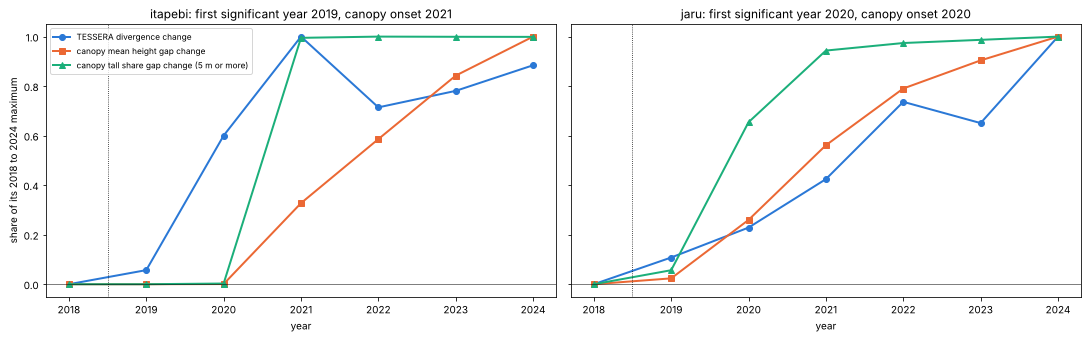

itapebi: onset 2021, sign positive; dD against the mean height gap change: Pearson +0.70, Spearman +0.75; against the tall share gap change: Pearson +0.85, Spearman +0.63 (7 years)


,dD,site height (m),control height (m),site tall share,control tall share,height gap change (m),tall share gap change
2018,0.0000,0.0394,0.0306,0.0069,0.0044,0.0000,0.0000
2019,0.0268,0.0394,0.0308,0.0069,0.0044,-0.0001,0.0000
2020,0.2825,0.0607,0.0384,0.0112,0.0059,0.0136,0.0028
2021,0.4707,6.3483,0.0618,0.9941,0.0084,6.2778,0.9832
2022,0.3362,11.3295,0.0824,0.9993,0.0087,11.2383,0.9882
2023,0.3676,16.2679,0.1050,0.9993,0.0095,16.1542,0.9874
2024,0.4162,19.2940,0.1097,0.9993,0.0098,19.1756,0.9871


jaru: onset 2020, sign positive; dD against the mean height gap change: Pearson +0.97, Spearman +0.96; against the tall share gap change: Pearson +0.86, Spearman +0.96 (7 years)


,dD,site height (m),control height (m),site tall share,control tall share,height gap change (m),tall share gap change
2018,0.0000,0.0810,0.3842,0.0116,0.0466,0.0000,0.0000
2019,0.0069,0.4286,0.4114,0.0672,0.0487,0.3203,0.0534
2020,0.0147,3.6484,0.4305,0.6333,0.0497,3.5210,0.6185
2021,0.0273,7.7639,0.4578,0.9093,0.0522,7.6093,0.8921
2022,0.0474,10.8980,0.4859,0.9397,0.0538,10.7152,0.9209
2023,0.0419,12.4917,0.5394,0.9551,0.0571,12.2555,0.9330
2024,0.0644,13.8336,0.5788,0.9689,0.0585,13.5579,0.9454


In [12]:
def canopy_frame(key: str) -> pd.DataFrame:
    """The divergence change and the canopy gaps per canopy year, for one run."""
    s = reports[key]["summary"]
    cn = s["canopy"]
    dd = trajectory(reports[key])["divergence_change"]
    rows = {}
    for y, r in cn["per_year"].items():
        rows[int(y)] = {
            "dD": dd[int(y)],
            "site height (m)": r["site_mean_m"],
            "control height (m)": r["control_mean_m"],
            "site tall share": r["site_tall_share"],
            "control tall share": r["control_tall_share"],
            "height gap change (m)": r["gap_change_mean_m"],
            "tall share gap change": r["gap_change_tall_share"],
        }
    return pd.DataFrame(rows).T


fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained", sharey=True)
for ax, key in zip(axes, ("itapebi", "jaru"), strict=True):
    cf = canopy_frame(key)
    yrs = cf.index.to_numpy()
    for col, colour, marker, label in (
        ("dD", BLUE, "o", "TESSERA divergence change"),
        ("height gap change (m)", ORANGE, "s", "canopy mean height gap change"),
        ("tall share gap change", AQUA, "^", "canopy tall share gap change (5 m or more)"),
    ):
        v = cf[col].to_numpy()
        ax.plot(yrs, v / np.nanmax(v), color=colour, marker=marker, linewidth=2, label=label)
    s = reports[key]["summary"]
    ax.axvline(s["planted"] - 0.5, color="black", linewidth=0.8, linestyle=":")
    ax.axhline(0, color="black", linewidth=0.5)
    ax.set_xlabel("year")
    ax.set_title(
        f"{key}: first significant year {s['significant_years'][0]}, canopy onset {s['canopy']['canopy_onset_year']}"
    )
axes[0].set_ylabel("share of its 2018 to 2024 maximum")
axes[0].legend(loc="upper left", fontsize="small")
plt.show()
for key in ("itapebi", "jaru"):
    cn = reports[key]["summary"]["canopy"]
    print(
        f"{key}: onset {cn['canopy_onset_year']}, sign {cn['correlation_sign']}; "
        f"dD against the mean height gap change: Pearson {cn['pearson_divergence_vs_mean_gap_change']:+.2f}, "
        f"Spearman {cn['spearman_divergence_vs_mean_gap_change']:+.2f}; "
        f"against the tall share gap change: Pearson {cn['pearson_divergence_vs_tall_gap_change']:+.2f}, "
        f"Spearman {cn['spearman_divergence_vs_tall_gap_change']:+.2f} ({cn['correlation_years']} years)"
    )
    display(canopy_frame(key))

**Itapebi: the embeddings lead the canopy layer.** GLAD shows nothing on the site through 2020 (0.06 m mean, 1% of
pixels of 5 m or more): the onset is 2021, when 99% of the site jumps to 5 m or more. The TESSERA divergence is
already significant in 2019 (site preparation, which is not trees and which no canopy layer could see) and at 60% of
its peak in 2020, when the young trees are under 5 m. The lead is at least one year for the trees themselves. After
2021 the two part ways: canopy height keeps climbing (6.4, 11.3, 16.3, 19.3 m) while `dD` stays on its plateau. The
embeddings register the change of land cover, not tree height. The correlation (Pearson 0.70, Spearman 0.75 over 7
years) is positive but carried by the step; with seven points, read its sign.

**Jaru: they move together**, with `dD` first significant in 2020, the same year as the canopy onset (63% of the site
of 5 m or more), and a near-linear relation after (Pearson 0.97). Regrowth is gradual, so both curves rise
gradually. Section 10 shows that the embeddings moved at Jaru a year before this window starts.

On both sites the control's canopy barely moves (Itapebi's control 0.03 to 0.11 m, Jaru's 0.38 to 0.58 m), and the
target is flat by construction of the layer (section 2).

## 9. The negative sites: no divergence expected

Each demo's negative feature is a pasture of about the site's size that stayed pasture (GLAD 0 m every year,
WorldCover grassland, no Hansen loss), run exactly as a site with the same planting year:
`--aoi itapebi:negative` and `--aoi jaru:negative`. A good method calls both quiet.

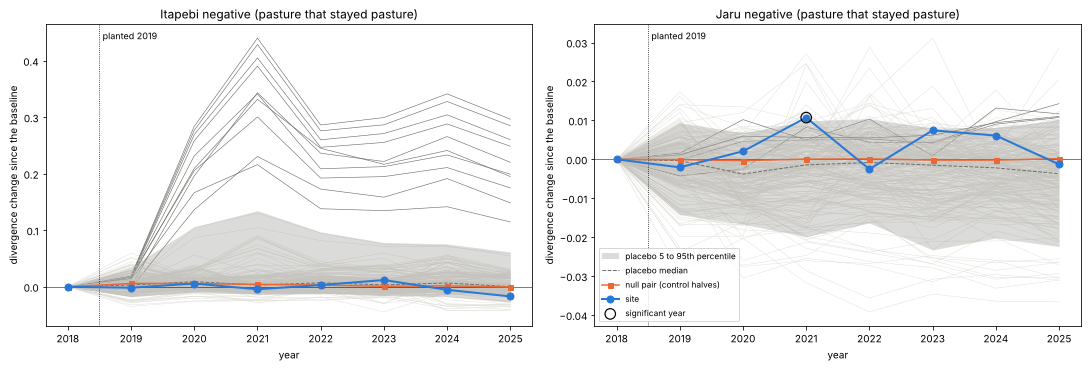

itapebi_negative: no divergence detected (The divergence change stays within the placebo band in every post-planting year.)
  dD after planting from -0.0171 to +0.0119; band p95 from 0.0350 to 0.1347; Theil-Sen -0.0014 per year
  placebo false positive rate 5.0%; null test no divergence detected, max |dD| 0.00587, ratio to the site 0.343
jaru_negative: no divergence detected (The divergence change exceeds the placebo band in 2021, but not in every year through 2025.)
  dD after planting from -0.0025 to +0.0107; band p95 from 0.0068 to 0.0104; Theil-Sen +0.0001 per year
  placebo false positive rate 2.0%; null test no divergence detected, max |dD| 0.00033, ratio to the site 0.031


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), layout="constrained")
trajectory_panel(axes[0], "itapebi_negative", title="Itapebi negative (pasture that stayed pasture)")
trajectory_panel(axes[1], "jaru_negative", title="Jaru negative (pasture that stayed pasture)")
axes[1].legend(loc="lower left", fontsize="small")
plt.show()
for key in ("itapebi_negative", "jaru_negative"):
    s = reports[key]["summary"]
    n = s["null_test"]
    t = s["trend"]
    post = trajectory(reports[key]).query("post_planting")
    print(
        f"{key}: {s['verdict']} ({s['verdict_detail']})\n"
        f"  dD after planting from {post['divergence_change'].min():+.4f} to {post['divergence_change'].max():+.4f}; "
        f"band p95 from {post['placebo_p95'].min():.4f} to {post['placebo_p95'].max():.4f}; "
        f"Theil-Sen {t['theil_sen_slope']:+.4f} per year\n"
        f"  placebo false positive rate {s['placebo_false_positive_rate']:.1%}; null test {n['null_verdict']}, "
        f"max |dD| {n['null_max_abs_change']:.5f}, ratio to the site {n['null_to_site_ratio']:.3f}"
    )

**Both negatives are quiet.** At Itapebi the negative's `dD` stays between -0.017 and +0.012 after planting, against
the planted site's 0.03 to 0.47. At Jaru it stays between -0.003 and +0.011, crossing the band once, in 2021 (0.0107
against 0.0099): one significant year, which the verdict rule (every year from Y to 2025, at least two) does not call
a divergence. The trend is flat (Theil-Sen 0.0001 per year). Both null tests pass.

**But the Itapebi negative's band is wide**, up to 0.135 in 2021 against about 0.01 to 0.06 for the other runs, and
10 of its 200 placebos (5%) are themselves called diverging, all since 2020. The map below shows why: the
negative's ring holds land that changed.

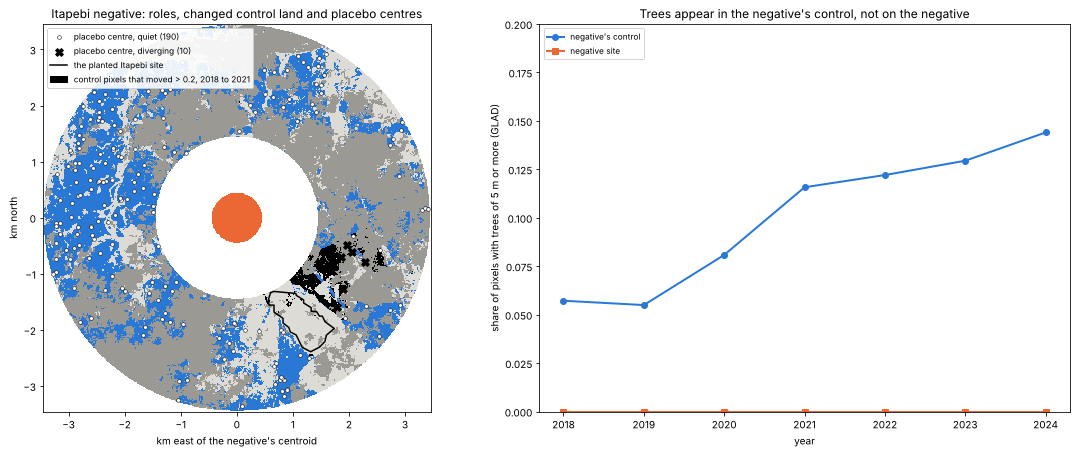

the planted Itapebi site's pixels in the negative's run: {'matched control': 148, 'ring rejected by the filter': 5468, 'no match-year data, or dropped by the panel rule': 584}


In [14]:
nb, ntr, ncrs = load_cog("itapebi_negative")
nrole = nb["role"]
nh, nw = nrole.shape
neg_geom = demo.demo_feature("itapebi", "negative")
nc = gpd.GeoSeries([neg_geom], crs=4326).to_crs(ncrs).iloc[0].centroid
NORIGIN = (nc.x, nc.y)
NEXT = [
    (ntr.c - NORIGIN[0]) / 1e3,
    (ntr.c + nw * ntr.a - NORIGIN[0]) / 1e3,
    (ntr.f + nh * ntr.e - NORIGIN[1]) / 1e3,
    (ntr.f - NORIGIN[1]) / 1e3,
]
p = pd.read_parquet(RUNS["itapebi_negative"][1] / "restore_placebos.parquet").groupby("placebo").first()
p["diverging"] = p["verdict"].str.startswith("diverging")
planted_site = km_frame(site_geom, ncrs, NORIGIN)
# Control pixels whose distance from the control mean grew by more than 0.2 between 2018 and 2021.
moved_map = np.where(nrole == 2, nb["similarity_to_control_2018"] - nb["similarity_to_control_2021"], np.nan)
moved_mask = np.ma.masked_where(~(moved_map > 0.2), np.ones_like(moved_map))

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(15, 6.2), layout="constrained", gridspec_kw={"width_ratios": [1, 1.1]})
ax0.imshow(np.ma.masked_invalid(nrole), cmap=cmap, vmin=0.5, vmax=5.5, extent=NEXT, interpolation="nearest")
ax0.imshow(moved_mask, cmap=ListedColormap(["black"]), extent=NEXT, interpolation="nearest")
quiet = p[~p["diverging"]]
loud = p[p["diverging"]]
ax0.scatter(
    (quiet.centre_x - NORIGIN[0]) / 1e3,
    (quiet.centre_y - NORIGIN[1]) / 1e3,
    s=14,
    color="white",
    edgecolors="black",
    linewidths=0.5,
    label=f"placebo centre, quiet ({len(quiet)})",
)
ax0.scatter(
    (loud.centre_x - NORIGIN[0]) / 1e3,
    (loud.centre_y - NORIGIN[1]) / 1e3,
    s=60,
    marker="X",
    color="black",
    label=f"placebo centre, diverging ({len(loud)})",
)
draw_outline(ax0, planted_site, color="black", linewidth=1.5, label="the planted Itapebi site")
ax0.set_xlabel("km east of the negative's centroid")
ax0.set_ylabel("km north")
ax0.legend(
    handles=[
        *ax0.get_legend_handles_labels()[0],
        Patch(color="black", label="control pixels that moved > 0.2, 2018 to 2021"),
    ],
    loc="upper left",
    fontsize="small",
    framealpha=0.9,
)
ax0.set_title("Itapebi negative: roles, changed control land and placebo centres")
cf = canopy_frame("itapebi_negative")
ax1.plot(cf.index, cf["control tall share"], color=BLUE, marker="o", linewidth=2, label="negative's control")
ax1.plot(cf.index, cf["site tall share"], color=ORANGE, marker="s", linewidth=2, label="negative site")
ax1.set_ylim(0, 0.2)
ax1.set_xlabel("year")
ax1.set_ylabel("share of pixels with trees of 5 m or more (GLAD)")
ax1.legend(loc="upper left", fontsize="small")
ax1.set_title("Trees appear in the negative's control, not on the negative")
plt.show()

site_mask = rasterize(
    [(gpd.GeoSeries([site_geom], crs=4326).to_crs(ncrs).iloc[0], 1)], out_shape=nrole.shape, transform=ntr
).astype(bool)
v, k = np.unique(nrole[site_mask], return_counts=True)
print(
    "the planted Itapebi site's pixels in the negative's run:",
    {ROLE_LABELS[int(a)]: int(b) for a, b in zip(v, k, strict=True)},
)

The negative lies 1 km northwest of the planted site, so the planted site falls inside the negative's 1 to 3 km
ring. The filter rejects almost all of it (in 2017 the planted block did not look like the negative's pasture): only
148 of its pixels end up in the negative's control. The wide band has another source: **trees appear across the
negative's control** (its share of pixels of 5 m or more rises from 5.7% in 2018 to 14.4% in 2024). The black pixels
on the map are control land that moved away from the control mean by more than 0.2 between 2018 and 2021: one
patch, starting at the planted site's northern edge and running about a kilometre north and east of it, and the 10
diverging placebos sit on it, 0.7 to 1.6 km from the planted site's centroid. The cell below checks that the
diverging placebos are the ones that landed on such land: it takes, for every placebo, the control pixels within its radius and their change in distance
from the control mean between 2018 and 2021 (from the COG's `similarity_to_control_<year>` bands).

In [15]:
xy_rc = np.nonzero(nrole == 2)
cx_m = ntr.c + (xy_rc[1] + 0.5) * ntr.a
cy_m = ntr.f + (xy_rc[0] + 0.5) * ntr.e
moved = nb["similarity_to_control_2018"][xy_rc] - nb["similarity_to_control_2021"][xy_rc]
radius = reports["itapebi_negative"]["summary"]["placebos"]["radius_m"]
per_placebo = []
for _, row in p.iterrows():
    near = np.hypot(cx_m - row.centre_x, cy_m - row.centre_y) <= radius
    per_placebo.append(
        {"diverging": row.diverging, "mean change": moved[near].mean(), "share moved > 0.2": np.mean(moved[near] > 0.2)}
    )
per_placebo = pd.DataFrame(per_placebo)
display(per_placebo.groupby("diverging").agg(["count", "median", "min", "max"]))
print(f"share of the whole control that moved more than 0.2 from 2018 to 2021: {np.mean(moved > 0.2):.1%}")

mean change                         share moved > 0.2                        
                count  median     min     max             count  median     min     max
diverging                                                                              
False             190 -0.0012 -0.0692  0.2166               190  0.0000  0.0000  0.4812
True               10  0.3692  0.3017  0.4290                10  0.7953  0.6278  0.9076

share of the whole control that moved more than 0.2 from 2018 to 2021: 5.5%


They are: under the 10 diverging placebos the control pixels moved away from the control mean by about 0.37 between
2018 and 2021, and roughly four in five of them by more than 0.2; under the 190 quiet ones the change is about zero.
About 5% of the negative's control moved that much, enough for one placebo in twenty to land on it, and those
placebos widen the band. What is that land? The same canopy layer, on the run's grid, over the changed pixels and the
rest of the control (store metadata only, the GLAD tiles are cached by the runs):

In [16]:
reader = io.TesseraReader.open()  # store metadata and coordinates only, no embedding chunk
to_lonlat = Transformer.from_crs(ncrs, 4326, always_xy=True)
x0, y0 = to_lonlat.transform(ntr.c, ntr.f + nh * ntr.e)
x1, y1 = to_lonlat.transform(ntr.c + nw * ntr.a, ntr.f)
zp = io.plan_aoi(reader, shapely.box(x0, y0, x1, y1)).zones[0]


def on_glad_grid(heights: np.ndarray, mask: np.ndarray) -> np.ndarray:
    """GLAD heights (on the plan's grid) at the COG pixels of ``mask``."""
    r, c = np.nonzero(mask)
    x = ntr.c + (c + 0.5) * ntr.a
    y = ntr.f + (r + 0.5) * ntr.e
    gr = np.floor((zp.transform.f - y) / -zp.transform.e).astype(int)
    gc = np.floor((x - zp.transform.c) / zp.transform.a).astype(int)
    ok = (gr >= 0) & (gr < heights.shape[0]) & (gc >= 0) & (gc < heights.shape[1])
    return heights[gr[ok], gc[ok]]


changed = np.isfinite(moved_map) & (moved_map > 0.2)
unchanged = np.isfinite(moved_map) & ~(moved_map > 0.2)
rows = {}
for year in (2018, 2019, 2020, 2021, 2022, 2024):
    h = validate.glad_tch(zp, year)
    a, b = on_glad_grid(h, changed), on_glad_grid(h, unchanged)
    rows[year] = {
        f"changed land ({a.size:,} px): mean m": np.nanmean(a),
        "changed land: share 5 m or more": np.nanmean(a >= 5),
        f"rest of the control ({b.size:,} px): mean m": np.nanmean(b),
        "rest of the control: share 5 m or more": np.nanmean(b >= 5),
    }
display(pd.DataFrame(rows).T)
print(f"store bytes read for the plan: {reader.bytes_read:,}")

,"changed land (5,136 px): mean m",changed land: share 5 m or more,"rest of the control (88,830 px): mean m",rest of the control: share 5 m or more
2018,0.0214,0.0025,0.4577,0.0604
2019,0.0210,0.0025,0.4405,0.0580
2020,2.0849,0.4153,0.4667,0.0615
2021,7.6871,0.9613,0.5053,0.0669
2022,12.5611,0.9825,0.5523,0.0723
2024,18.9683,0.9887,0.7798,0.0952


store bytes read for the plan: 48,809


The changed land is a planting: no tree of 5 m on it in 2018 and 2019, 42% of it in 2020, 96% in 2021 and 19 m by
2024, the same course as the demo block, a year ahead. The demo polygon is one compartment of a larger planting, and
the negative's ring holds about 51 ha of another. So the negative's control does hold a treated parcel: not the demo
block itself (the filter rejected all but 148 of its pixels, which did not look like the negative's pasture in 2017)
but the neighbouring compartment, which did.

So the negative is quiet partly because its band is wide. Is it quiet on its own? The check below rebuilds the band
from the 190 placebos the verdict rule calls quiet:

In [17]:
rows = {}
for key in RUNS:
    wide, diverging = placebo_changes(key)
    tr = trajectory(reports[key])
    p95_quiet = wide[~diverging.to_numpy()].quantile(0.95)
    post = tr["post_planting"]
    above = [int(y) for y in tr.index[post] if tr.loc[y, "divergence_change"] > max(p95_quiet[y], 0.0)]
    rows[key] = {
        "diverging placebos": int(diverging.sum()),
        "largest band p95 after planting": tr.loc[post, "placebo_p95"].max(),
        "same, quiet placebos only": p95_quiet[post.to_numpy()].max(),
        "site years above the quiet band": ", ".join(map(str, above)) or "none",
    }
display(pd.DataFrame(rows).T)

,diverging placebos,largest band p95 after planting,"same, quiet placebos only",site years above the quiet band
itapebi,5,0.0629,0.0619,"2019, 2020, 2021, 2022, 2023, 2024, 2025"
itapebi_negative,10,0.1347,0.0599,none
jaru,2,0.0168,0.0164,"2020, 2021, 2022, 2023, 2024, 2025"
jaru_negative,4,0.0104,0.0105,2021


Against the band of the quiet placebos alone (p95 at most 0.060), the Itapebi negative is still never significant,
and the other three runs keep the same significant years. The negative's quiet call does not depend on the
inflated band.

Two smaller things about the negatives:

- **The Itapebi negative has 2017 data on 14% of its pixels** (908 of 6,267), so its control is matched to that 14%
  of the site; the run warns. The trajectory uses all 6,267 pixels (all have data from 2018 on).
- **Their `departed_fraction` falls below the baseline** (Itapebi negative 0.048 to 0.000, Jaru negative 0.091 to
  0.017). When part of the control changes (trees appearing, clearing), the control's own low tail of similarity
  widens, and a site that stayed put falls below it less often. A negative change is what "stable while the
  surroundings change" looks like; it is not a fault.

## 10. Jaru: natural regrowth as a contrast

Jaru is the case the brief had in mind for "a working restoration diverges steadily from control". No one planted it;
trees came back on an abandoned paddock. The figure puts the two sites side by side: the divergence (each with its own
band, on its own scale, since Jaru's is about a seventh of Itapebi's), and the progress toward each demo's mature stand,
which is on a common scale.

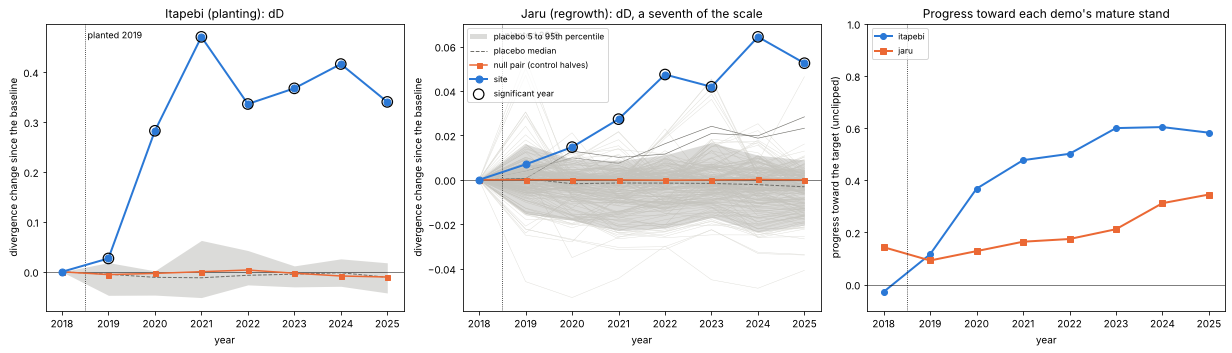

,divergence,divergence_change,placebo_p95,significant,null_divergence_change,target_progress,closer_to_target_fraction,departed_fraction
year,,,,,,,,
2018,0.0720,0.0000,0.0000,False,0.0000e+00,0.1432,0.0091,0.4330
2019,0.0789,0.0069,0.0162,False,4.6722e-05,0.0922,0.0075,0.2747
2020,0.0867,0.0147,0.0094,True,8.1370e-05,0.1281,0.0166,0.6160
2021,0.0993,0.0273,0.0086,True,-1.5033e-05,0.1642,0.0339,0.7730
2022,0.1194,0.0474,0.0112,True,-1.7216e-04,0.1746,0.0571,0.8057
2023,0.1139,0.0419,0.0168,True,-5.7972e-05,0.2122,0.0838,0.7582
2024,0.1364,0.0644,0.0111,True,1.5023e-04,0.3121,0.1564,0.9545
2025,0.1245,0.0525,0.0089,True,-1.6242e-05,0.3452,0.0998,0.7372


jaru trend after planting: Theil-Sen 0.0087 per year (95% interval 0.0053 to 0.0135), Spearman rho 0.93 (p 0.003)


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), layout="constrained")
trajectory_panel(axes[0], "itapebi", title="Itapebi (planting): dD", show_placebos=False)
trajectory_panel(axes[1], "jaru", title="Jaru (regrowth): dD, a seventh of the scale", show_placebos=True)
axes[1].legend(loc="upper left", fontsize="small")
for key, colour, marker in (("itapebi", BLUE, "o"), ("jaru", ORANGE, "s")):
    tr = trajectory(reports[key])
    axes[2].plot(tr.index, tr["target_progress"], color=colour, marker=marker, linewidth=2, label=key)
axes[2].axhline(0, color="black", linewidth=0.5)
axes[2].axvline(2018.5, color="black", linewidth=0.8, linestyle=":")
axes[2].set_ylim(-0.1, 1.0)
axes[2].set_xlabel("year")
axes[2].set_ylabel("progress toward the target (unclipped)")
axes[2].legend(loc="upper left", fontsize="small")
axes[2].set_title("Progress toward each demo's mature stand")
plt.show()
display(
    trajectory(reports["jaru"])[
        [
            "divergence",
            "divergence_change",
            "placebo_p95",
            "significant",
            "null_divergence_change",
            "target_progress",
            "closer_to_target_fraction",
            "departed_fraction",
        ]
    ]
)
t = reports["jaru"]["summary"]["trend"]
print(
    f"jaru trend after planting: Theil-Sen {t['theil_sen_slope']:.4f} per year "
    f"(95% interval {t['theil_sen_low']:.4f} to {t['theil_sen_high']:.4f}), "
    f"Spearman rho {t['spearman_rho']:.2f} (p {t['spearman_p']:.3f})"
)

**Jaru diverges the way the brief describes a working restoration: steadily.** `dD` grows from 0.007 in 2019 to
0.064 in 2024 (0.053 in 2025), significant from 2020, with a Theil-Sen slope of 0.0087 per year (interval 0.0053 to
0.0135) and Spearman rho 0.93 (p 0.003). Itapebi is the opposite shape: a jump, then a plateau.

**The size differs by a factor of about seven.** A closed eucalyptus canopy replaces pasture block-wide in two years;
regrowth on a paddock is a mix of shrubs, young trees and grass for years. Toward the targets, Jaru's progress goes
from 0.14 to 0.35 and only 10 to 16% of its pixels are closer to the mature stand than to the control by 2024 and
2025, while Itapebi's plantation reaches 0.6 and 99%. The embeddings put a six-year-old monoculture nearer to native
forest than six years of natural regrowth. That is a statement about canopy closure and spectral and radar
similarity, not about ecological value, and it is a warning against reading `progress` as "how restored".

**Jaru's baseline is not clean.** The table compares the match year with the baseline for all four runs:

In [19]:
rows = {}
for key, rep in reports.items():
    c = rep["summary"]["control"]
    rows[key] = {
        "D in 2017 (match year)": c["match_year_divergence"],
        "D in 2018 (baseline), same pixels": c["baseline_divergence_match_pixels"],
        "selection drift": c["selection_drift"],
        "baseline D above this share of placebos": c["balance"]["baseline_divergence_rank"],
        "departed fraction at the baseline": rep["summary"]["departed_fraction_baseline"],
        "site tall share 2018 (GLAD)": rep["summary"]["canopy"]["per_year"]["2018"]["site_tall_share"],
    }
display(pd.DataFrame(rows).T)

,D in 2017 (match year),"D in 2018 (baseline), same pixels",selection drift,baseline D above this share of placebos,departed fraction at the baseline,site tall share 2018 (GLAD)
itapebi,0.0502,0.0489,-0.0014,0.755,0.0466,0.0069
itapebi_negative,0.0241,0.0317,0.0077,0.785,0.0482,0.0000
jaru,0.0250,0.0720,0.0470,1.000,0.4330,0.0116
jaru_negative,0.0123,0.0149,0.0026,0.615,0.0913,0.0000


Between 2017 and 2018 Jaru's divergence from its control jumps from 0.025 to 0.072 (a drift of 0.047, against -0.001
to 0.008 for the other three runs), its baseline divergence is above every placebo's, and 43% of its pixels have
already left the control's range at the 2018 baseline. GLAD sees 1% of the site at 5 m or more in 2018. The demo's own
notes describe "shrubby dirty pasture" in the 2018 and 2019 imagery. So the regrowth had started by 2018, before
the canopy layer could see it, and the embeddings saw it. The run warns about this ("The site already differs from
its control at the baseline 2018") whenever the baseline divergence is above 95% of the placebos'.

Two consequences:

- `dD` is measured from the 2018 baseline, so **it leaves out the first part of the change** (the 0.047 between 2017
  and 2018 is about three quarters of the 0.064 that `dD` reaches in 2024). "Diverging from control since 2020" is
  late, not early, for this site.
- The "planting year" of a regrowth site is a choice, and the app's answer depends on it. Here the embeddings
  suggest 2018. `--planted 2018` would move the baseline to 2017, the store's sparse first year, and the match onto
  the baseline itself, and the app warns about both (section 12).

On the canopy check Jaru agrees closely with GLAD (Pearson 0.97), because inside the 2018 to 2024 window both measure
the same gradual change; the lead of the embeddings sits in the 2017 to 2018 step, outside that window.

## 11. An honest reading

What the numbers show:

- **The app separates change from no change on these four sites.** The planted site is called diverging from 2019,
  its planting year, with `dD` up to 0.47 against a band that never exceeds 0.063. The regrowth site is called
  diverging from 2020 with a steady rise. Both negatives are quiet (the Itapebi one even against a band rebuilt
  from its quiet placebos), and all four null tests are flat (largest null change 0.010, at most 3% of the site's
  largest change on the diverging sites).
- **The embeddings see a planting before a tree height model does**: a year before the first tree reaches 5 m at
  Itapebi, and at Jaru the regrowth shows in 2018, two years before GLAD's onset.
- **The per-pixel numbers are clear when the change is**: at Itapebi 99% of pixels are closer to the forest target
  than to the control from 2023, against 0.4% of the control's.

What they do not show:

- **There is no accuracy here.** With no global reference for restoration outcomes, the null test, the placebos and
  the negatives show that the method stays quiet where nothing happened; they do not measure how often it is right
  about real projects. Two synthetic sites picked with GLAD canopy height (so the canopy check agrees with them by
  construction) and two hand-picked negatives are a demonstration, not a validation.
- **Divergence is not "restored".** The plantation scores higher on every number than the natural regrowth: larger
  divergence, more progress toward native forest, more pixels closer to it. A monoculture is not a restoration
  success. What the app can tell a buyer is that the land changed relative to comparable land, how much, from when,
  and toward what reference; whether the change is the one promised needs the right target and a visit.
- **The baseline year is load-bearing.** Jaru's regrowth began before its nominal year and the baseline absorbed
  part of it. A project's real start date matters more than any setting of the app.
- **2017 is weak.** It is the match year of every demo run, the Itapebi ring has data on 43% of its pixels that year
  and the Itapebi negative on 14%. The control is drawn from where 2017 had clear views.
- **The band depends on the control.** Where the control itself changes (the Itapebi negative's ring), the band
  widens and a real but small divergence would be harder to call. The report's `placebo_false_positive_rate` cannot
  flag this (it is capped near 5% by construction); the count of diverging placebos and a look at their centres can.
- **The canopy correlation rests on seven points** and is dominated by one step at Itapebi. Read its sign.

## 12. Running it on your own site

```
tessera-apps restore --aoi my_site.geojson --planted 2020 --target mature_stand.geojson --validate --out out/my_site
```

- **The site** is a polygon file in any CRS (points and lines are an error), of at least 0.25 ha and 25 pixels with
  data. The site, the control and the target must not overlap.
- **The planting year.** `planted <= 2017` is refused (the store starts in 2017, so there is no pre-planting year). The
  baseline is `planted - 1` and the match year the year before it. For a regrowth site, pick the year the change
  began from imagery, not the year it became visible to a canopy layer (section 10).
- **Minimum post-planting years.** The verdict needs at least 3 years from `planted` to `year_b` (`--min-post-years`),
  so with the store ending in 2025, `planted` can be at most 2023; and "diverging" needs at least two significant years
  ending in the last year.
- **The 2017 caveat.** `--planted 2018` puts the baseline on 2017, the store's first year: few Sentinel-2
  observations and sparse valid pixels in places, and no earlier year to match the control on, so the filter and the
  baseline share one year (regression to the mean). The app warns. With `--planted 2019` (the demos) 2017 is the match
  year; the run warns when under half of the site or the ring has 2017 data, as at Itapebi.
- **`--match-year`** moves the control filter to another year, from 2017 to `year_a`. `--match-year 2018` for a 2019
  planting matches on the baseline itself: full coverage, but the regression-to-the-mean drift then lands inside `dD`,
  and the run warns.
- **`--control my_control.geojson`** replaces the ring with a polygon you choose without the embeddings (for example
  a neighbouring parcel under the same management that was not planted). It is used as given, with no filter, and
  its baseline balance against the site is reported (`share_below_threshold`, the baseline rank among the placebos);
  the run warns when it is poorly matched. Its null test splits it along its long axis.
- **`--target`** is optional; without it you get the divergence and `departed_fraction`, not the progress or
  `closer_to_target_fraction`. Choose the target for the question: a mature stand of the same kind of planting for
  "on track", a native stand for "becoming forest". Prefer 200 or more pixels (the run warns below).
- **Other options**: `--ring-inner-km` and `--ring-outer-km` (1 and 3 by default, at most 10), `--control-pct` (5),
  `--folds` (5), `--fold-cell-m` (200; smaller for a small site), `--placebos` (200), `--seed`, `--no-canopy`,
  `--strict-validate` (exit 3 when the canopy layer or the null test cannot be done), `--force`.

In Python: `run_restore("my_site.geojson", Path("out/my_site"), planted=2020, target="mature_stand.geojson",
validate=True)`.

## 13. Cost

Bytes read and wall time come from each run's report; peak memory was measured from outside with `/usr/bin/time -v`
on the CLI runs (maximum resident set). The app's memory estimate is an upper bound used to warn before any read.

In [20]:
PEAK_RSS_KIB = {"itapebi": 1_151_772, "itapebi_negative": 1_662_968, "jaru": 1_622_256, "jaru_negative": 1_807_852}
CLI_WALL_S = {"itapebi": 18.70, "itapebi_negative": 44.12, "jaru": 28.94, "jaru_negative": 36.18}
rows = {}
for key, rep in reports.items():
    t = rep["timings"]
    rows[key] = {
        "bytes read": f"{rep['bytes_read'] / 1e9:.2f} GB",
        "estimate (upper bound)": f"{rep['estimated_bytes'] / 1e9:.2f} GB",
        "stage 1 (match year)": f"{t['stage1']:.1f} s",
        "stage 2 (trajectory years)": f"{t['stage2']:.1f} s",
        "placebos and trajectories": f"{t['placebos'] + t['trajectories']:.1f} s",
        "write": f"{t['write']:.1f} s",
        "wall (report)": f"{t['wall_s']:.1f} s",
        "wall (CLI, measured)": f"{CLI_WALL_S[key]:.1f} s",
        "memory estimate": f"{rep['estimated_memory'] / 1e9:.2f} GB",
        "peak memory (measured)": f"{PEAK_RSS_KIB[key] * 1024 / 1e9:.2f} GB",
    }
display(pd.DataFrame(rows))
print(f"bytes read note: {reports['itapebi']['bytes_read_note']}")

,itapebi,itapebi_negative,jaru,jaru_negative
bytes read,0.77 GB,0.89 GB,1.03 GB,1.04 GB
estimate (upper bound),1.12 GB,1.12 GB,1.37 GB,1.37 GB
stage 1 (match year),8.2 s,3.5 s,3.9 s,3.7 s
stage 2 (trajectory years),11.7 s,9.9 s,9.8 s,10.1 s
placebos and trajectories,0.9 s,3.4 s,3.1 s,4.4 s
write,2.0 s,1.9 s,1.9 s,2.0 s
wall (report),27.4 s,23.1 s,22.9 s,24.0 s
"wall (CLI, measured)",18.7 s,44.1 s,28.9 s,36.2 s
memory estimate,2.59 GB,2.57 GB,2.52 GB,2.52 GB
peak memory (measured),1.18 GB,1.70 GB,1.66 GB,1.85 GB


bytes read note: Chunk payload bytes returned by the zarr store (io.CountingStore), gap bytes of merged range requests included. Icechunk manifest and snapshot fetches below the zarr interface are not counted.


Each run reads 0.77 to 1.04 GB, most of it in stage 2: the eight trajectory years for the chunks that hold a site, kept
control or target pixel (a chunk with no kept pixel is never read again after the match year). An identical rerun
of the Itapebi command was skipped in 2.3 s, reading only store metadata, left every output untouched and printed
what the first run read. `rio cogeo validate` accepts all four COGs. The network test
(`pytest -m network tests/test_restore_network.py`) runs the Itapebi command end to end against the live store and
GLAD and passed in 28 s.